# Credit Risk Data Cleaning & Preprocessing Pipeline
**Missão:** construir um pipeline em Python de saneamento avançado e engenharia de features que receba a base de dados corrompida e entregar um dataset perfeitamente higienizado e padronizado (Model-Ready) para a equipe de Ciência de Dados.

# 1. Diagnóstico e tratamento de valores faltantes
## 1.1. Análise exploratória

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler

# Carrega o arquivo .CSV
df_clientes_credito = pd.read_csv('clientes_credito_bruto.csv') #leitura do arquivo CSV e transforma em DATAFRAME

# Configura o pandas para não quebrar linhas no print
pd.set_option('display.width', 1000)
pd.set_option('display.max_columns', None)

# Análise exploratória rápida
print(df_clientes_credito.shape)
print()
print(df_clientes_credito.head())
print()
print(df_clientes_credito.dtypes)
print()
print(df_clientes_credito.describe())

(2500, 8)

  id_cliente  idade  renda_mensal  tempo_emprego_anos  divida_total  score_credito estado_civil   escolaridade
0  CLI-10000   44.0       6782.82                17.7      22213.24          703.0       Casado  Pós-Graduação
1  CLI-10001   36.3       7987.19                 3.1      24022.43          397.0       Casado       Superior
2  CLI-10002   45.8       3282.01                 0.0      15407.56          449.0     Solteiro       Superior
3  CLI-10003   56.3       3687.20                 0.7       9598.35          731.0   Divorciado  Pós-Graduação
4  CLI-10004   35.2       2915.41                 1.7       9834.37          454.0       Casado    Fundamental

id_cliente             object
idade                 float64
renda_mensal          float64
tempo_emprego_anos    float64
divida_total          float64
score_credito         float64
estado_civil           object
escolaridade           object
dtype: object

             idade  renda_mensal  tempo_emprego_anos   divida_total

## 1.2. Diagnóstico de valores faltantes ou nulos


In [2]:
df_clientes_credito = df_clientes_credito.copy()

# Contagem absoluta e percentual de nulos por coluna
nulos_abs = df_clientes_credito.isna().sum()
nulos_pct = (df_clientes_credito.isna().sum() / len(df_clientes_credito)) * 100

tabela_diagnostico = pd.DataFrame({
    'Nulos_Absolutos': nulos_abs,
    'Porcentagem (%)': nulos_pct.round(2)
})

print("=== DIAGNÓSTICO INICIAL DE DADOS AUSENTES ===")
display(tabela_diagnostico[tabela_diagnostico['Nulos_Absolutos'] > 0])
print()
print(f"Total de nulos na base: {df_clientes_credito.isna().sum().sum()}")

=== DIAGNÓSTICO INICIAL DE DADOS AUSENTES ===


,Nulos_Absolutos,Porcentagem (%)
idade,100,4.0
renda_mensal,150,6.0
tempo_emprego_anos,125,5.0
estado_civil,125,5.0
escolaridade,125,5.0



Total de nulos na base: 625


### Análise
Esse diagnóstico mostrou que 25% dos dados estavam nulos ou ausentes. Sendo assim optou-se por não excluir sumariamente os registros que continham dados nulos ou ausentes, pois representam uma quantidade significativa do conteúdo total da base de dados. A abordagem escolhida foi o tratamento desses valores nulos, através da imputação de dados baseado no tipo de dado ausente ou nulo.

## 1.3. Imputação categórica utilizando a `MODA`
Realizar a imputação utilizando a moda nas variáveis qualitativas e categóricas. São elas: `estado_civil` e `escolaridade`.

In [3]:
# Calculando a Moda (valor mais frequente)
moda_estado_civil = df_clientes_credito['estado_civil'].mode()[0]
moda_escolaridade = df_clientes_credito['escolaridade'].mode()[0]

print(f"Moda de 'estado_civil': {moda_estado_civil}")
print(f"Moda de 'escolaridade': {moda_escolaridade}")

# Preenchendo os nulos usando .fillna()
df_clientes_credito['estado_civil'] = df_clientes_credito['estado_civil'].fillna(moda_estado_civil)
df_clientes_credito['escolaridade'] = df_clientes_credito['escolaridade'].fillna(moda_escolaridade)

print("\n[Sucesso] Variáveis categóricas imputadas com a Moda!")
print()
print(f"Total de nulos restantes na base: {df_clientes_credito.isna().sum().sum()}")

Moda de 'estado_civil': Casado
Moda de 'escolaridade': Médio

[Sucesso] Variáveis categóricas imputadas com a Moda!

Total de nulos restantes na base: 375


## 1.4. Imputação utilizando a `MEDIANA`
Realizar a imputação utilizando a mediana nas variáveis numéricas `tempo_emprego_anos` e `idade`.

In [4]:
media_renda = df_clientes_credito['renda_mensal'].mean()
mediana_renda = df_clientes_credito['renda_mensal'].median()

print(f"Média da Renda (Distorcida por Outlier): R$ {media_renda:.2f}")
print(f"Mediana da Renda (Robusta):              R$ {mediana_renda:.2f}")

# Imputando a mediana nas colunas 'tempo_emprego_anos' e 'idade'
mediana_tempo_emprego = df_clientes_credito['tempo_emprego_anos'].median()
mediana_idade = df_clientes_credito['idade'].median()

df_clientes_credito['tempo_emprego_anos'] = df_clientes_credito['tempo_emprego_anos'].fillna(mediana_tempo_emprego)
df_clientes_credito['idade'] = df_clientes_credito['idade'].fillna(mediana_idade)

print("\n[Sucesso] Imputação por Mediana concluída em 'tempo_emprego_anos' e 'idade'!")
print()
print(f"Total de nulos restantes na base: {df_clientes_credito.isna().sum().sum()}")

Média da Renda (Distorcida por Outlier): R$ 816278.67
Mediana da Renda (Robusta):              R$ 5297.06

[Sucesso] Imputação por Mediana concluída em 'tempo_emprego_anos' e 'idade'!

Total de nulos restantes na base: 150


# 1.5. Imputação utilizando o algoritmo K-Nearest Neighbors (KNN)
O KNN prevê o rótulo de um novo ponto, olhando para os K pontos mais próximos dele no espaço de características. O algoritmo KNN foi utilizado na variável numérica `renda_mensal`. As variáveis `idade`, `tempo_emprego_anos` e `divida_total`, foram utilizadas para os cálculos do algoritmo.

In [5]:
imputer_knn = KNNImputer(n_neighbors=5)

cols_numericas = ['idade', 'tempo_emprego_anos', 'divida_total', 'renda_mensal']

# Aplicando o KNNImputer na coluna de renda
dados_imputados = imputer_knn.fit_transform(df_clientes_credito[cols_numericas])
df_clientes_credito[cols_numericas] = pd.DataFrame(dados_imputados, columns=cols_numericas)

print("=== CONFERÊNCIA FINAL DE NULOS PÓS-IMPUTAÇÃO ===")
print(f"Total de nulos restantes na base: {df_clientes_credito.isna().sum().sum()}")

=== CONFERÊNCIA FINAL DE NULOS PÓS-IMPUTAÇÃO ===
Total de nulos restantes na base: 0


# 2. Detecção de valores impossíveis e tratamento de outliers
## 2.1. Filtragem de valores impossíveis e anomalias biológicas
Remover as idades com valor negativo, acima de 120 anos (por ser muito raro) e as idades menores que 17 anos, pois é obrigatório ter pelo menos 18 anos completos ou ser legalmente emancipado para solicitar um empréstimo pessoal ou consignado.

In [6]:
qtd_antes = len(df_clientes_credito)

# Descartando idades biologicamente impossíveis
df_clientes_credito = df_clientes_credito[(df_clientes_credito['idade'] >= 18) & (df_clientes_credito['idade'] <= 120)].copy()

qtd_depois = len(df_clientes_credito)
print(f"Registros impossíveis removidos: {qtd_antes - qtd_depois}")
print()
print(df_clientes_credito.describe())

Registros impossíveis removidos: 15

             idade  renda_mensal  tempo_emprego_anos   divida_total  score_credito
count  2485.000000  2.485000e+03         2485.000000    2485.000000    2485.000000
mean     38.523944  7.723497e+05            4.608290   18923.364447     621.544869
std      11.103928  2.683481e+07            5.951873   36018.062752     110.462493
min      18.000000  1.542650e+03            0.000000    1316.330000     300.000000
25%      30.800000  4.014510e+03            1.400000   10745.150000     547.000000
50%      38.300000  5.298900e+03            3.200000   14718.180000     622.000000
75%      45.700000  7.115090e+03            6.000000   20455.580000     699.000000
max      75.000000  1.000000e+09          105.000000  647395.480000     850.000000


## 2.2. Cálculo de quartis, IQR e limites

In [7]:
def calcular_limites_iqr(df, coluna, truncar_zero=True, teto_maximo=None):
    q1 = df[coluna].quantile(0.25)
    q3 = df[coluna].quantile(0.75)
    iqr = q3 - q1
    limite_inf = q1 - 1.5 * iqr
    limite_sup = q3 + 1.5 * iqr

    """O limite inferior de 'renda_mensal', 'divida_total' e 'tempo_emprego_anos' estava ficando negativo devido ao cálculo matemático.
       O limite inferior foi truncado em zero."""

    #Não permite números negativos
    if truncar_zero:
        limite_inf = max(0.0, limite_inf)

    #Limita ao teto máximo informado
    if teto_maximo is not None:
        limite_sup = teto_maximo

    return limite_inf, limite_sup, iqr

# Lista de colunas numéricas que serão analisadas
colunas_analise = ['renda_mensal', 'divida_total', 'tempo_emprego_anos']

outliers_por_coluna = {} # Dicionário para armazenar os outliers de cada coluna para possível uso futuro.
limites_por_coluna = {} # Dicionário para armazenar os limites de cada coluna para possível uso futuro.

for col in colunas_analise:
    teto = 35.0 if col == 'tempo_emprego_anos' else None # Define o teto de 35 anos exclusivamente para tempo_emprego_anos

    lim_inf, lim_sup, iqr = calcular_limites_iqr(df_clientes_credito, col, teto_maximo=teto)

    limites_por_coluna[col] = {'lim_inf': lim_inf, 'lim_sup': lim_sup} # Armazena os limites encontrados

    # Identifica registros abaixo do limite inferior ou acima do limite superior
    outliers = df_clientes_credito[
        (df_clientes_credito[col] < lim_inf) | (df_clientes_credito[col] > lim_sup) # Filtra e retorna True para registros fora dos limites normais do IQR (outliers)
    ]
    outliers_por_coluna[col] = outliers

    print(f"\n=== LIMITES DE TUKEY PARA: {col.upper()} ===")
    print(f"Q1 (25%):           {df_clientes_credito[col].quantile(0.25):.2f}")
    print(f"Q3 (75%):           {df_clientes_credito[col].quantile(0.75):.2f}")
    print(f"IQR (Dispersão):    {iqr:.2f}")
    print(f"Limite Inferior:    {lim_inf:.2f}")
    print(f"Limite Superior:    {lim_sup:.2f}")
    print(f"Total de outliers:  {len(outliers)} ({len(outliers) / len(df_clientes_credito) * 100:.2f}%)")


=== LIMITES DE TUKEY PARA: RENDA_MENSAL ===
Q1 (25%):           4014.51
Q3 (75%):           7115.09
IQR (Dispersão):    3100.58
Limite Inferior:    0.00
Limite Superior:    11765.96
Total de outliers:  66 (2.66%)

=== LIMITES DE TUKEY PARA: DIVIDA_TOTAL ===
Q1 (25%):           10745.15
Q3 (75%):           20455.58
IQR (Dispersão):    9710.43
Limite Inferior:    0.00
Limite Superior:    35021.23
Total de outliers:  81 (3.26%)

=== LIMITES DE TUKEY PARA: TEMPO_EMPREGO_ANOS ===
Q1 (25%):           1.40
Q3 (75%):           6.00
IQR (Dispersão):    4.60
Limite Inferior:    0.00
Limite Superior:    35.00
Total de outliers:  7 (0.28%)


### Análise
Foram calculados os quartis, intervalo interquartis, limite inferior e limite superior. O limite inferior nas variáveis `renda_mensal`, `divida_total` e `tempo_emprego_anos` estava ficando negativo devido ao cálculo matemático. Como é impossível realmente existir renda, dívida e tempo de emprego com valores negativos, foi tomada a decisão de truncar o limite inferior com valor zero.

Outro ponto observado foi na variável `tempo_emprego_anos`, onde o limite superior calculado teve o resultado de 12.9 anos. Historicamente, 35 anos de trabalho/contribuição são considerados o mais comum para se aposentar, mesmo com as novas regras de aposentadoria que usa a idade como fator para cálculo.

Na base de dados, existem muitos registros de valores entre 12.9 e 35 anos, e somente 7 registros com valores acima de 35 anos. Então, foi configurado no código para que o limite superior fosse definido com o valor em 35 anos. Isso fez com que o número de outliers fosse reduzido consideravelmente.

Essa decisão foi tomada pois registros com tempo de emprego superior a 12.9 anos seriam prejudicados na hora do cálculo para análise de crédito, uma vez que, o maior o tempo de emprego pode indicar maior estabilidade financeira.

## 2.3. Aplicação do método de Capping (Winsorization)
Utilizar o método de Capping (Winsorization) para substituir os valores que ultrapassam os limites de segurança pelo valor do próprio limite máximo, que foi definido no passo 2.2 com o valor de 35 anos.

In [8]:
for col, limites in limites_por_coluna.items():
    col_tratada = f"{col}_tratada"

    # Reaproveita os limites diretamente do dicionário criado no passo 2.2, sem precisar recalcular.
    df_clientes_credito[col_tratada] = np.clip(
        df_clientes_credito[col],
        a_min=limites['lim_inf'],
        a_max=limites['lim_sup']
    )

    prefixo = "R$ " if col != 'tempo_emprego_anos' else ""

    print(f"[Sucesso] Capping aplicado na coluna '{col_tratada}'!")
    print(f"Novo Valor Máximo após Capping: {prefixo}{df_clientes_credito[col_tratada].max():.2f}\n")
print(df_clientes_credito.describe())
print()
# Ordena do maior para o menor e exibe os 10 maiores
print(df_clientes_credito['tempo_emprego_anos_tratada'].sort_values(ascending=False).head(10))

[Sucesso] Capping aplicado na coluna 'renda_mensal_tratada'!
Novo Valor Máximo após Capping: R$ 11765.96

[Sucesso] Capping aplicado na coluna 'divida_total_tratada'!
Novo Valor Máximo após Capping: R$ 35021.23

[Sucesso] Capping aplicado na coluna 'tempo_emprego_anos_tratada'!
Novo Valor Máximo após Capping: 35.00

             idade  renda_mensal  tempo_emprego_anos   divida_total  score_credito  renda_mensal_tratada  divida_total_tratada  tempo_emprego_anos_tratada
count  2485.000000  2.485000e+03         2485.000000    2485.000000    2485.000000           2485.000000           2485.000000                 2485.000000
mean     38.523944  7.723497e+05            4.608290   18923.364447     621.544869           5739.030005          16254.468573                    4.473843
std      11.103928  2.683481e+07            5.951873   36018.062752     110.462493           2348.129893           7409.795706                    4.429367
min      18.000000  1.542650e+03            0.000000    1316.3

# 3. Engenharia de features - Discretização, normalização e correlações
## 3.1. Discretização de variáveis (Binning)
Criar uma variável categórica ordinal chamada `faixa_etaria`, onde o valor contínuo da variável `idade`, é transformado em valores discretos (Jovem, Adulto e Sênior) utilizando o método pd.cut.

In [9]:
df_transform = df_clientes_credito.copy()

# Definindo os pontos de corte e os rótulos ordinais das faixas
limites_idade = [17, 29, 59, 100]
rotulos_idade = ['Jovem', 'Adulto', 'Sênior']

# Criando a nova variável ordinal 'faixa_etaria'
df_transform['faixa_etaria'] = pd.cut(
    df_transform['idade'],
    bins=limites_idade,
    labels=rotulos_idade
)

print("=== DISTRIBUIÇÃO DA NOVA VARIÁVEL 'faixa_etaria' ===")
print(df_transform['faixa_etaria'].value_counts())
print()
display(df_transform[['idade', 'faixa_etaria']].head(5))

=== DISTRIBUIÇÃO DA NOVA VARIÁVEL 'faixa_etaria' ===
faixa_etaria
Adulto    1876
Jovem      512
Sênior      97
Name: count, dtype: int64



,idade,faixa_etaria
0,44.0,Adulto
1,36.3,Adulto
2,45.8,Adulto
3,56.3,Adulto
4,35.2,Adulto


## 3.2. Escalonamento
Realizar o escalonamento de todas as variáveis numéricas contínuas para equalizar a magnitude das variáveis. O método utilizado é o `MinMaxScaler`.

In [10]:
cols_continuas = ['idade', 'renda_mensal_tratada', 'tempo_emprego_anos_tratada', 'divida_total_tratada', 'score_credito']

scaler_minmax = MinMaxScaler()

# Nomes das novas colunas
cols_minmax = [f'{col}_minmax' for col in cols_continuas]

# Atribui o resultado diretamente no df_transform
df_transform[cols_minmax] = scaler_minmax.fit_transform(df_transform[cols_continuas])

display(df_transform[['idade', 'idade_minmax', 'renda_mensal_tratada', 'renda_mensal_tratada_minmax', 'tempo_emprego_anos_tratada', 'tempo_emprego_anos_tratada_minmax', 'divida_total_tratada', 'divida_total_tratada_minmax', 'score_credito', 'score_credito_minmax']].head(2))

,idade,idade_minmax,renda_mensal_tratada,renda_mensal_tratada_minmax,tempo_emprego_anos_tratada,tempo_emprego_anos_tratada_minmax,divida_total_tratada,divida_total_tratada_minmax,score_credito,score_credito_minmax
0,44.0,0.456140,6782.82,0.512571,17.7,0.505714,22213.24,0.619996,703.0,0.732727
1,36.3,0.321053,7987.19,0.630377,3.1,0.088571,24022.43,0.673674,397.0,0.176364


## 3.3. Limpeza do dataframe
Após todo o tratamento da base de dados, será realizada a limpeza do dataframe. Serão excluídas as colunas com os dados originais brutos: `renda_mensal`, `divida_total`, `tempo_emprego_anos`. As demais colunas serão renomeadas para facilitar a busca e a leitura.

In [11]:
# Remove as colunas originais sem tratamento
df_final = df_transform.drop(columns=['renda_mensal', 'divida_total', 'tempo_emprego_anos']).copy()

# Renomeia as novas colunas tratadas
dicionario_nomes = {
    'renda_mensal_tratada': 'renda_mensal',
    'divida_total_tratada': 'divida_total',
    'tempo_emprego_anos_tratada': 'tempo_emprego_anos',
    'idade_minmax': 'idade_scale',
    'score_credito_minmax': 'score_scale',
    'renda_mensal_tratada_minmax': 'renda_scale',
    'divida_total_tratada_minmax': 'divida_scale',
    'tempo_emprego_anos_tratada_minmax': 'tempo_emprego_scale'
}

df_final.rename(columns=dicionario_nomes, inplace=True)
display(df_final.head(3))

,id_cliente,idade,score_credito,estado_civil,escolaridade,renda_mensal,divida_total,tempo_emprego_anos,faixa_etaria,idade_scale,renda_scale,tempo_emprego_scale,divida_scale,score_scale
0,CLI-10000,44.0,703.0,Casado,Pós-Graduação,6782.82,22213.24,17.7,Adulto,0.456140,0.512571,0.505714,0.619996,0.732727
1,CLI-10001,36.3,397.0,Casado,Superior,7987.19,24022.43,3.1,Adulto,0.321053,0.630377,0.088571,0.673674,0.176364
2,CLI-10002,45.8,449.0,Solteiro,Superior,3282.01,15407.56,0.0,Adulto,0.487719,0.170137,0.000000,0.418077,0.270909


## 3.4. Cálculo da matriz de correlação de Pearson
Realizar o cálculo da matriz de correlação de Pearson utilizando todas as variáveis contínuas que tiveram seus valores escalonados.

In [12]:
# Calculando a matriz de correlação das variáveis contínuas
colunas_heatmap = ['idade_scale', 'renda_scale', 'tempo_emprego_scale', 'divida_scale', 'score_scale']
matriz_corr = df_final[colunas_heatmap].corr(method='pearson')

print("=== MATRIZ DE CORRELAÇÃO DE PEARSON ===")
print()
display(matriz_corr.round(2))

=== MATRIZ DE CORRELAÇÃO DE PEARSON ===



,idade_scale,renda_scale,tempo_emprego_scale,divida_scale,score_scale
idade_scale,1.00,-0.00,0.03,0.01,0.03
renda_scale,-0.00,1.00,-0.03,0.74,-0.01
tempo_emprego_scale,0.03,-0.03,1.00,-0.04,-0.01
divida_scale,0.01,0.74,-0.04,1.00,-0.01
score_scale,0.03,-0.01,-0.01,-0.01,1.00


## 3.5. Heatmap de correlação

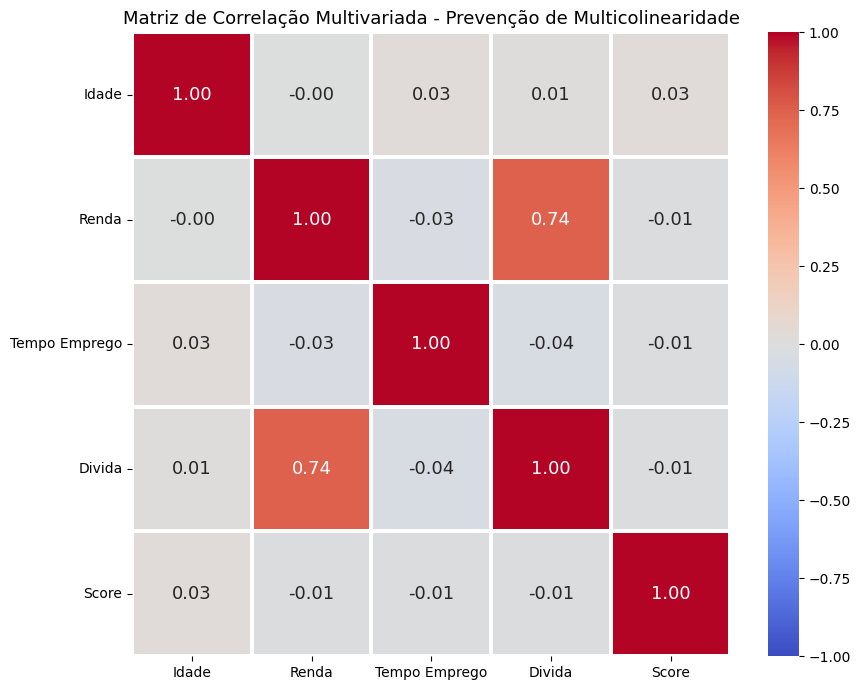


[Sucesso] Imagem 'heatmap_correlacoes_TP2.png' gerada e salva com sucesso!


In [13]:
plt.figure(figsize=(9, 7))

# Renomeia apenas a matriz temporária (remove '_scale' e substitui '_' por espaço)
nomes_limpos = {
    col: col.replace('_scale', '').replace('_', ' ').title()
    for col in colunas_heatmap
}
matriz_corr_limpa = matriz_corr.rename(index=nomes_limpos, columns=nomes_limpos)

# Desenhando o Heatmap anotado com paleta divergente 'coolwarm'
sns.heatmap(
    matriz_corr_limpa,
    annot=True,          # Exibe os números em cada célula
    annot_kws={'fontsize': 13},
    fmt=".2f",           # Formatação com 2 casas decimais
    cmap="coolwarm",     # Paleta de cores (Azul=Negativo, Vermelho=Positivo)
    center=0,
    vmin=-1, vmax=1,     # Limites do mapa de cor
    linewidths=1.5,      # Espaçamento entre as células

)

plt.title("Matriz de Correlação Multivariada - Prevenção de Multicolinearidade", fontsize=13)
plt.yticks(rotation=0)
plt.tight_layout()

# Salvando a figura para uso no relatório do TP2
plt.savefig("heatmap_correlacoes_TP2.png", dpi=300)
plt.show()
print()
print("[Sucesso] Imagem 'heatmap_correlacoes_TP2.png' gerada e salva com sucesso!")

### Análise
Foi feita a plotagem do Heatmap de correlação utilizando a biblioteca Seaborn. No Heatmap é possível notar que a única correlação que chama mais atenção em toda a matriz ocorre entre renda e dívida, com um coeficiente positivo de `0.74`. Isso pode indicar que clientes com rendimentos mais elevados tendem a contrair dívidas maiores, pois conseguem maior acesso a linhas de crédito, cartões com limites altos e financiamentos.

# 4. Exportação do DataSet final higienizado

In [14]:
df_final.to_csv('clientes_credito_higienizado.csv', index=False, encoding='utf-8')
print("Arquivo exportado com sucesso!")

Arquivo exportado com sucesso!


# Conclusão Geral
Após a condução da análise de dados, é possível concluir a importância de conhecer a base de dados, bem como, o modelo de negócio da empresa para a tomada de decisão. Esse conhecimento impacta diretamente em como os dados serão tratados e nas abordagens que serão realizadas durante o processo de tratamento dos dados. Por exemplo, na etapa de filtragem de valores impossíveis, anomalias biológicas, cálculo dos quartis, intervalo interquartis, limite inferior, limite superior e capping, onde algumas variáveis continham resultados em valores negativos após o cálculo, bem como o limite superior do tempo de emprego, que apresentava um valor muito abaixo do tempo possível real.

Todo o processo do tratamento do dataset foi realizado visando deixar o novo modelo preditivo da empresa mais apurado, reduzindo o risco de inadimplência de novos proponentes e sendo mais justo na concessão de crédito pessoal.